In [1]:
import numpy as np

In [ ]:
class SGD:
    def __init__(self, lr=0.01):
        self.lr = lr

    def update(self, params, grads):
        for key in params:
            params[key] -= self.lr * grads[key]

In [ ]:
class Momentum:
    def __init__(self, lr=0.01, momentum=0.9):
        self.lr = lr
        self.momentum = momentum
        self.v = None

    # 相比于SGD，这个在更新的时候考虑了v本身，所以可以避免方向上的轻缓问题
    def update(self, params, grads):
        if self.v is None:
            self.v = {}
            for key, val in params.items():
                self.v[key] = np.zeros_like(val)

        for key in params:
            self.v[key] = self.momentum * self.v[key] - self.lr * grads[key]
            params[key] += self.v[key]

In [ ]:
class Adagrad:
    def __init__(self, lr=0.01):
        self.lr = lr
        self.h = None

    def update(self, params, grads):
        if self.h is None:
            self.h = {}
            for key, val in params.items():
                self.h[key] = np.zeros_like(val)

        for key in params:
            self.h[key] += grads[key] * grads[key]
            params[key] -= self.lr * grads[key] / (np.sqrt(self.h[key]) + 1e-7)

In [ ]:
class Adam:
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps

        self.step = 0
        self.m = None
        self.v = None

    def update(self, params, grads):
        # 只在第一次调用时初始化
        if self.m is None:
            self.m = {}
            self.v = {}

            for key, val in params.items():
                self.m[key] = np.zeros_like(val)
                self.v[key] = np.zeros_like(val)

        # 每次调用 update，次数加一
        self.step += 1

        for key in params:
            g = grads[key]

            # ① 梯度的历史平均
            self.m[key] = self.beta1 * self.m[key] + (1 - self.beta1) * g

            # ② 梯度平方的历史平均
            self.v[key] = self.beta2 * self.v[key] + (1 - self.beta2) * g**2

            # ③ 偏差校正
            m_hat = self.m[key] / (1 - self.beta1**self.step)
            v_hat = self.v[key] / (1 - self.beta2**self.step)

            # ④ 更新参数
            params[key] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

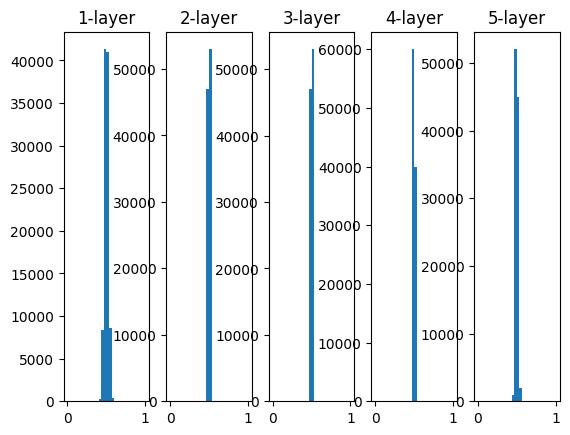

In [ ]:
import matplotlib.pyplot as plt
from common.functions import sigmoid

x = np.random.randn(1000,100)
node_num = 100
hidden_layer_size = 5
activations = {}

for i in range(hidden_layer_size):
    if i != 0:
        x = activations[i-1]

    w = np.random.randn(node_num,node_num)*1
    # w = np.random.randn(node_num,node_num) * 0.01

    z = np.dot(x,w)
    a = sigmoid(z)
    activations[i] = a

for i,a in activations.items():
    plt.subplot(1,len(activations),i+1)
    plt.title(str(i+1)+"-layer")
    plt.hist(a.flatten(),30,range = (0,1))

plt.show()